# Module 6: Final Data Science Project

## Student Performance Analysis and Prediction

### Project Overview
This project analyzes student performance data using Python, explores patterns in examination scores, and builds a Machine Learning model to predict student mathematics scores.

### Project Objectives
- Load and understand a real-world student performance dataset.
- Inspect and prepare data for analysis.
- Perform Exploratory Data Analysis (EDA).
- Create meaningful charts and visualizations.
- Identify patterns and relationships in student scores.
- Build a Machine Learning model for score prediction.
- Evaluate model performance using suitable metrics.
- Summarize findings and document the project conclusion.

### Tools and Technologies
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

### Expected Outcome
A complete Data Science project notebook containing data exploration, visualizations, a trained Machine Learning model, performance evaluation, and meaningful conclusions.

In [1]:

# Step 3: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Setup completed successfully!")


All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3
Setup completed successfully!


In [2]:

# Step 5: Load the Student Performance Dataset

import os

file_path = "/content/StudentsPerformance.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
else:
    print("Dataset file not found. Please check the filename in the Files panel.")

if "df" in globals():
    print("\nDataset shape:", df.shape)
    print("\nFirst 5 rows:")
    display(df.head())


Dataset loaded successfully!

Dataset shape: (1000, 8)

First 5 rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:

# Step 6: Inspect the Dataset

print("Dataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Dataset dimensions:
Rows: 1000
Columns: 8

Column names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Missing values in each column:


,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0



Total missing values: 0


In [4]:
# Step 7: Generate Summary Statistics

print("Summary Statistics of Student Performance")
display(df.describe())

print("\nAverage Math Score:", df["math score"].mean())
print("Average Reading Score:", df["reading score"].mean())
print("Average Writing Score:", df["writing score"].mean())

print("\nHighest Math Score:", df["math score"].max())
print("Lowest Math Score:", df["math score"].min())

Summary Statistics of Student Performance


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



Average Math Score: 66.089
Average Reading Score: 69.169
Average Writing Score: 68.054

Highest Math Score: 100
Lowest Math Score: 0


Average Exam Scores by Gender:


,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


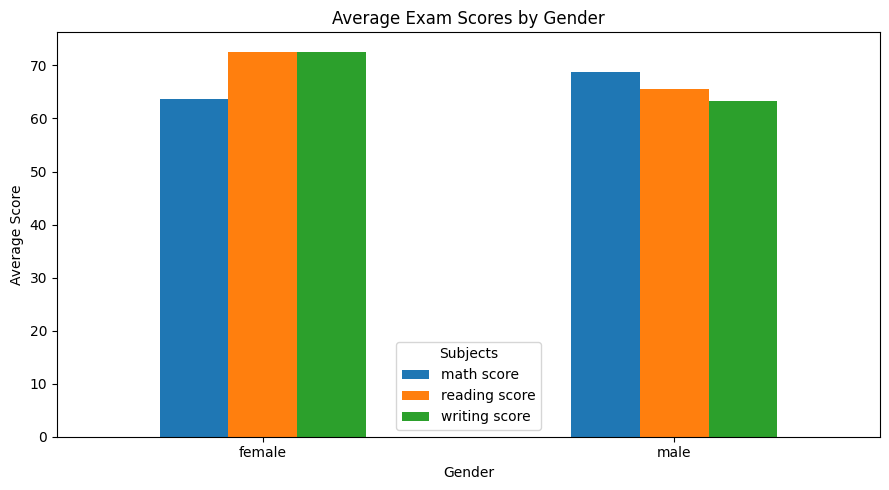

In [5]:
# Step 8: Analyze Student Scores by Gender

gender_scores = df.groupby("gender")[
    ["math score", "reading score", "writing score"]
].mean()

print("Average Exam Scores by Gender:")
display(gender_scores)

# Create a bar chart
gender_scores.plot(kind="bar", figsize=(9, 5))

plt.title("Average Exam Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")
plt.tight_layout()
plt.show()

Average Exam Scores by Test Preparation Course:


,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


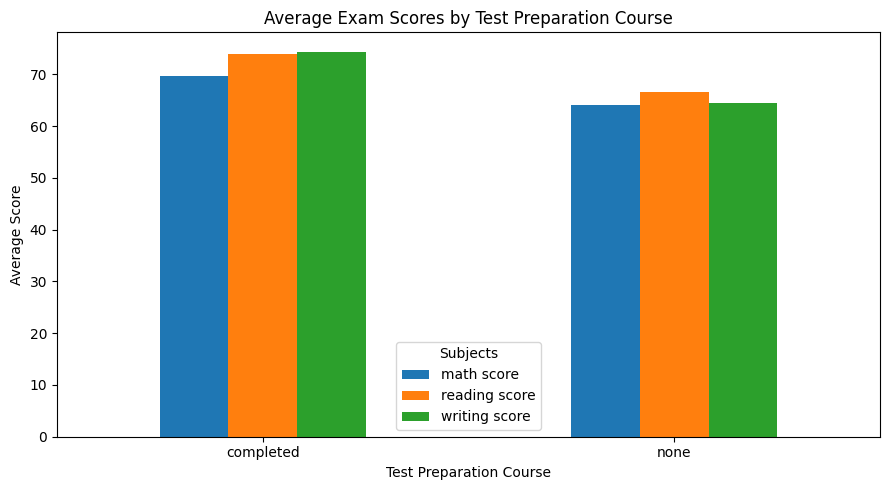

In [6]:
# Step 9: Analyze Scores by Test Preparation

prep_scores = df.groupby("test preparation course")[
    ["math score", "reading score", "writing score"]
].mean()

print("Average Exam Scores by Test Preparation Course:")
display(prep_scores)

# Create a bar chart
prep_scores.plot(kind="bar", figsize=(9, 5))

plt.title("Average Exam Scores by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")
plt.tight_layout()
plt.show()

Average Exam Scores by Parental Education:


,math score,reading score,writing score
parental level of education,,,
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
high school,62.137755,64.704082,62.448980
master's degree,69.745763,75.372881,75.677966
some college,67.128319,69.460177,68.840708
some high school,63.497207,66.938547,64.888268


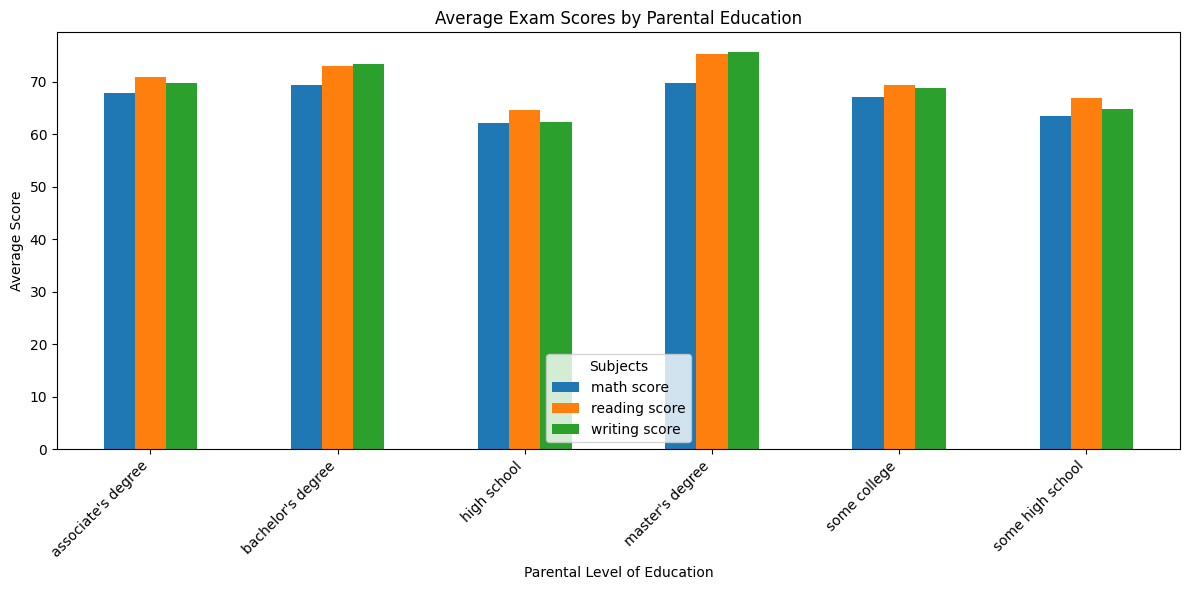

In [7]:
# Step 10: Analyze Scores by Parental Level of Education

parent_education_scores = df.groupby(
    "parental level of education"
)[
    ["math score", "reading score", "writing score"]
].mean()

print("Average Exam Scores by Parental Education:")
display(parent_education_scores)

# Create a bar chart
parent_education_scores.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Exam Scores by Parental Education")
plt.xlabel("Parental Level of Education")
plt.ylabel("Average Score")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Subjects")
plt.tight_layout()
plt.show()

Average Exam Scores by Lunch Type:


,math score,reading score,writing score
lunch,,,
free/reduced,58.921127,64.653521,63.022535
standard,70.034109,71.654264,70.823256


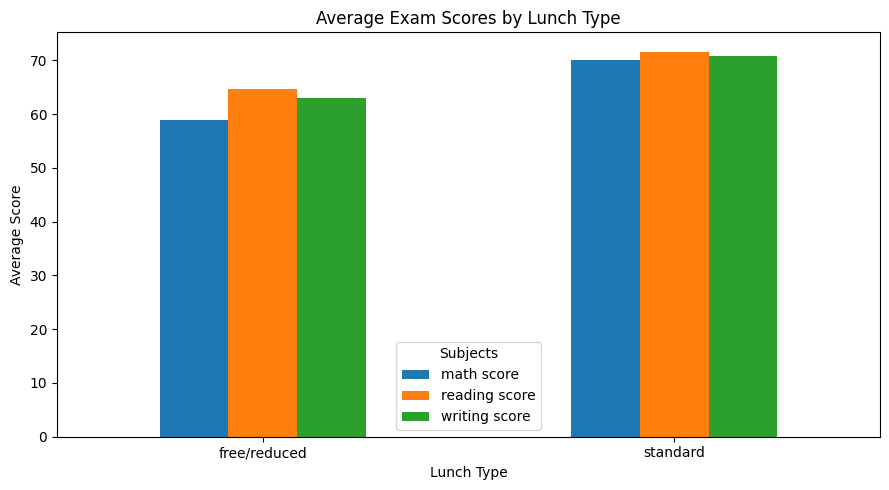

In [8]:
# Step 11: Analyze Scores by Lunch Type

lunch_scores = df.groupby("lunch")[
    ["math score", "reading score", "writing score"]
].mean()

print("Average Exam Scores by Lunch Type:")
display(lunch_scores)

# Create a bar chart
lunch_scores.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Exam Scores by Lunch Type")
plt.xlabel("Lunch Type")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")
plt.tight_layout()
plt.show()

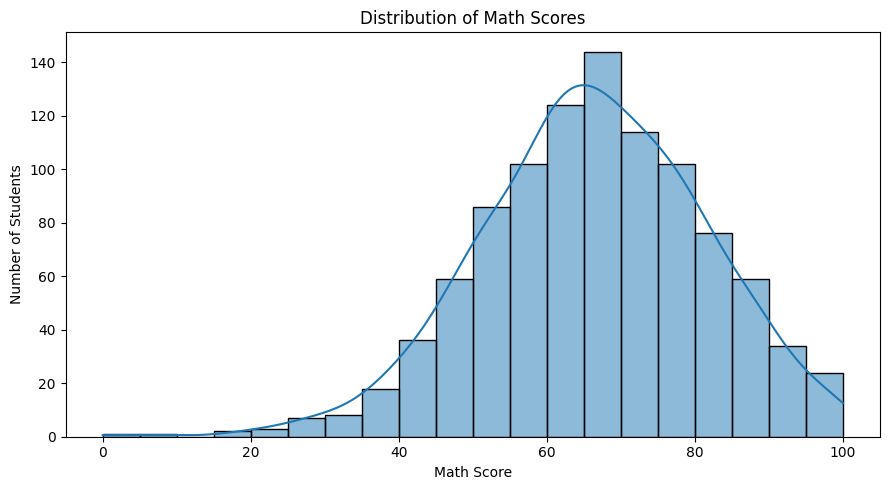

In [9]:
# Step 12: Distribution of Math Scores

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="math score",
    bins=20,
    kde=True
)

plt.title("Distribution of Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

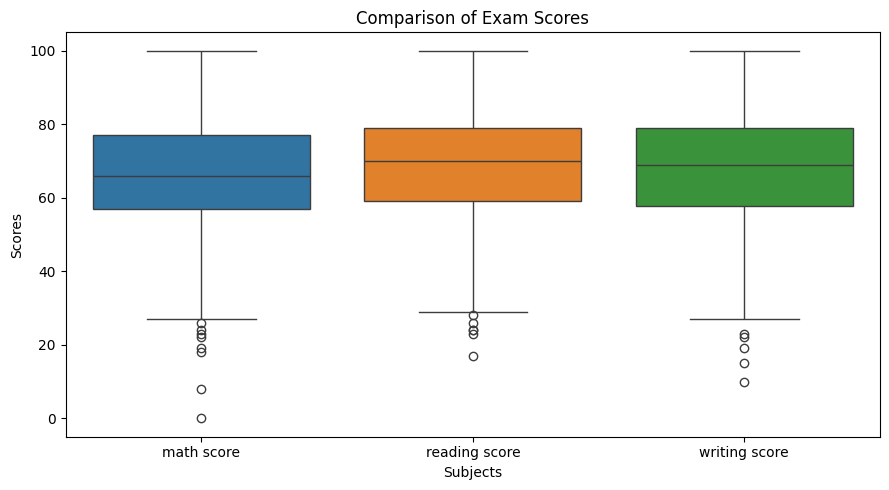

In [10]:
# Step 13: Box Plot of Exam Scores

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df[["math score", "reading score", "writing score"]]
)

plt.title("Comparison of Exam Scores")
plt.xlabel("Subjects")
plt.ylabel("Scores")
plt.tight_layout()
plt.show()

Correlation Between Exam Scores:


,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


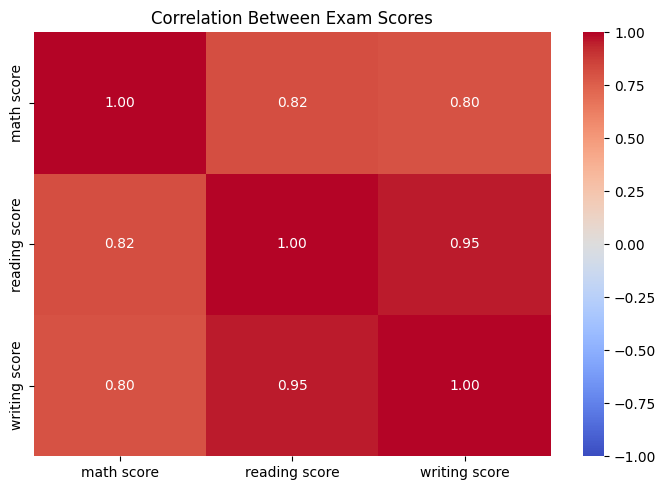

In [11]:
# Step 14: Correlation Heatmap

score_columns = [
    "math score",
    "reading score",
    "writing score"
]

correlation = df[score_columns].corr()

print("Correlation Between Exam Scores:")
display(correlation)

# Create a heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Exam Scores")
plt.tight_layout()
plt.show()

In [12]:
# Step 15: Create Total and Average Score Columns

df["total score"] = (
    df["math score"]
    + df["reading score"]
    + df["writing score"]
)

df["average score"] = df["total score"] / 3

print("New columns created successfully!")

print("\nStudent Scores:")
display(
    df[
        [
            "math score",
            "reading score",
            "writing score",
            "total score",
            "average score"
        ]
    ].head(10)
)

print("\nOverall Average Score:", round(df["average score"].mean(), 2))

New columns created successfully!

Student Scores:


,math score,reading score,writing score,total score,average score
0,72,72,74,218,72.666667
1,69,90,88,247,82.333333
2,90,95,93,278,92.666667
3,47,57,44,148,49.333333
4,76,78,75,229,76.333333
5,71,83,78,232,77.333333
6,88,95,92,275,91.666667
7,40,43,39,122,40.666667
8,64,64,67,195,65.000000
9,38,60,50,148,49.333333



Overall Average Score: 67.77


High-Performing Students (Average Score >= 80)
Number of high-performing students: 198

First 10 High-Performing Students:


,gender,math score,reading score,writing score,total score,average score
1,female,69,90,88,247,82.333333
2,female,90,95,93,278,92.666667
6,female,88,95,92,275,91.666667
16,male,88,89,86,263,87.666667
34,male,97,87,82,266,88.666667
35,male,81,81,79,241,80.333333
38,female,75,90,88,253,84.333333
49,male,82,84,82,248,82.666667
53,male,88,78,75,241,80.333333
54,female,71,84,87,242,80.666667


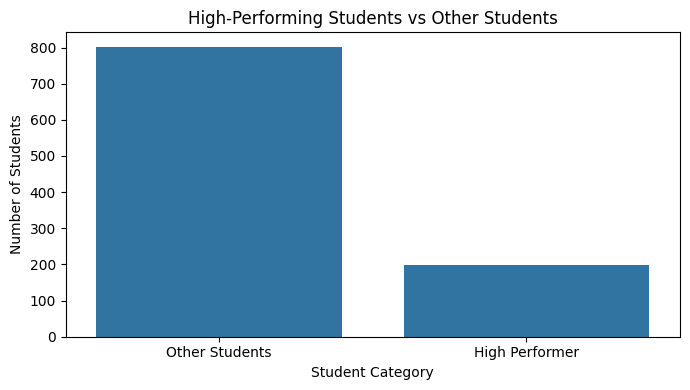

In [13]:
# Step 16: Identify High-Performing Students

high_performers = df[df["average score"] >= 80]

print("High-Performing Students (Average Score >= 80)")
print("Number of high-performing students:", len(high_performers))

print("\nFirst 10 High-Performing Students:")

display(
    high_performers[
        [
            "gender",
            "math score",
            "reading score",
            "writing score",
            "total score",
            "average score"
        ]
    ].head(10)
)

# Visualize the number of high-performing students
plt.figure(figsize=(7, 4))

sns.countplot(
    x=(df["average score"] >= 80).map({
        True: "High Performer",
        False: "Other Students"
    })
)

plt.title("High-Performing Students vs Other Students")
plt.xlabel("Student Category")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [14]:
# Step 17: Prepare Data for Machine Learning

# Select input features
X = df[["reading score", "writing score"]]

# Select the target variable
y = df["math score"]

print("Input Features (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

print("\nNumber of input rows:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Number of target values:", y.shape[0])

print("\nData prepared successfully!")

Input Features (X):


,reading score,writing score
0,72,74
1,90,88
2,95,93
3,57,44
4,78,75



Target Variable (y):


,math score
0,72
1,69
2,90
3,47
4,76



Number of input rows: 1000
Number of input features: 2
Number of target values: 1000

Data prepared successfully!


In [15]:
# Step 18: Split Data into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Dataset split successfully!")

print("\nTraining Data:")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTesting Data:")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Dataset split successfully!

Training Data:
X_train shape: (800, 2)
y_train shape: (800,)

Testing Data:
X_test shape: (200, 2)
y_test shape: (200,)

Training samples: 800
Testing samples: 200


In [16]:
# Step 19: Train the Linear Regression Model

# Create the model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

print("\nModel Coefficients:")
print("Reading Score Coefficient:", model.coef_[0])
print("Writing Score Coefficient:", model.coef_[1])

print("\nModel Intercept:", model.intercept_)

Linear Regression model trained successfully!

Model Coefficients:
Reading Score Coefficient: 0.5755599740328438
Writing Score Coefficient: 0.27176145521140394

Model Intercept: 7.85940588782988


In [17]:
# Step 20: Predict Students' Math Scores

# Make predictions using the testing data
y_pred = model.predict(X_test)

print("Math Score Predictions Generated Successfully!")

# Compare actual and predicted scores
comparison = pd.DataFrame({
    "Actual Math Score": y_test.values,
    "Predicted Math Score": y_pred.round(2)
})

print("\nFirst 10 Actual vs Predicted Scores:")
display(comparison.head(10))

print("\nTotal Predictions:", len(y_pred))

Math Score Predictions Generated Successfully!

First 10 Actual vs Predicted Scores:


,Actual Math Score,Predicted Math Score
0,91,80.19
1,53,65.68
2,80,69.44
3,74,72.02
4,84,76.83
5,81,72.22
6,69,65.27
7,54,59.82
8,87,69.44
9,51,50.08



Total Predictions: 200


In [18]:
# Step 21: Evaluate the Machine Learning Model

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-" * 35)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("R-squared Score (R²):", round(r2, 4))

print("\nModel evaluation completed successfully!")

Model Evaluation Results
-----------------------------------
Mean Absolute Error (MAE): 7.35
Mean Squared Error (MSE): 77.24
R-squared Score (R²): 0.6826

Model evaluation completed successfully!


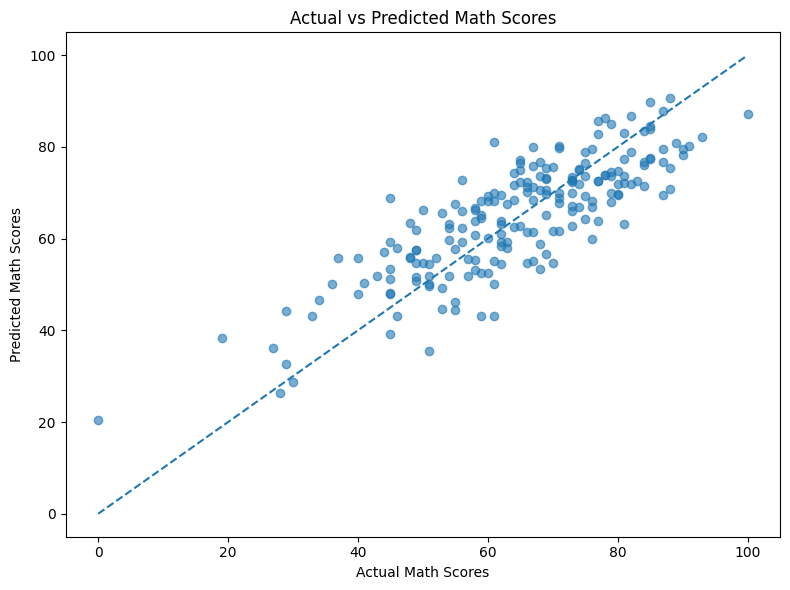

In [19]:
# Step 22: Actual vs Predicted Math Scores

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Reference line for perfect predictions
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--"
)

plt.title("Actual vs Predicted Math Scores")
plt.xlabel("Actual Math Scores")
plt.ylabel("Predicted Math Scores")
plt.tight_layout()
plt.show()

Prediction Error Analysis
-----------------------------------
Average Error: -0.38
Average Absolute Error: 7.35


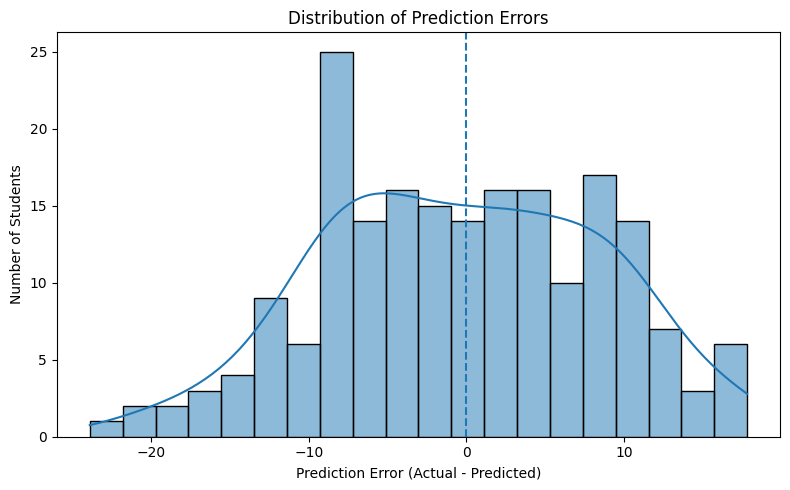

In [20]:
# Step 23: Analyze Prediction Errors

# Calculate prediction errors
errors = y_test - y_pred

print("Prediction Error Analysis")
print("-" * 35)

print("Average Error:", round(errors.mean(), 2))
print("Average Absolute Error:", round(errors.abs().mean(), 2))

# Plot the distribution of prediction errors
plt.figure(figsize=(8, 5))

sns.histplot(errors, bins=20, kde=True)

plt.axvline(0, linestyle="--")
plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [21]:
# Step 24: Predict Math Score for a New Student

# Example reading and writing scores
new_student = pd.DataFrame({
    "reading score": [75],
    "writing score": [80]
})

# Predict the student's math score
predicted_math_score = model.predict(new_student)[0]

print("New Student Score Prediction")
print("-" * 35)
print("Reading Score:", 75)
print("Writing Score:", 80)
print("Predicted Math Score:", round(predicted_math_score, 2))

print("\nPrediction completed successfully!")

New Student Score Prediction
-----------------------------------
Reading Score: 75
Writing Score: 80
Predicted Math Score: 72.77

Prediction completed successfully!


In [22]:
# Step 25: Final Project Findings

print("=" * 55)
print(" STUDENT PERFORMANCE ANALYSIS AND PREDICTION")
print("=" * 55)

print("\n1. DATASET INFORMATION")
print("Total students:", len(df))
print("Total columns:", df.shape[1])

print("\n2. AVERAGE SUBJECT SCORES")
print("Average Math Score:", round(df["math score"].mean(), 2))
print("Average Reading Score:", round(df["reading score"].mean(), 2))
print("Average Writing Score:", round(df["writing score"].mean(), 2))

print("\n3. HIGH-PERFORMING STUDENTS")
print("Students with average score >= 80:", len(high_performers))

print("\n4. MACHINE LEARNING MODEL")
print("Algorithm: Linear Regression")
print("Input Features: Reading Score and Writing Score")
print("Target: Math Score")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\n5. MODEL EVALUATION")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R-squared Score:", round(r2, 4))

print("\n" + "=" * 55)
print(" PROJECT SUMMARY COMPLETED")
print("=" * 55)

 STUDENT PERFORMANCE ANALYSIS AND PREDICTION

1. DATASET INFORMATION
Total students: 1000
Total columns: 10

2. AVERAGE SUBJECT SCORES
Average Math Score: 66.09
Average Reading Score: 69.17
Average Writing Score: 68.05

3. HIGH-PERFORMING STUDENTS
Students with average score >= 80: 198

4. MACHINE LEARNING MODEL
Algorithm: Linear Regression
Input Features: Reading Score and Writing Score
Target: Math Score
Training Samples: 800
Testing Samples: 200

5. MODEL EVALUATION
Mean Absolute Error: 7.35
Mean Squared Error: 77.24
R-squared Score: 0.6826

 PROJECT SUMMARY COMPLETED


# Conclusion

The Student Performance Analysis and Prediction project helped me understand how Python and data science can be used to analyze student exam results.

In this project, I used Pandas and NumPy to explore and analyze the dataset. I used Matplotlib and Seaborn to create visualizations, including bar charts, histograms, box plots, and a correlation heatmap.

I compared student scores based on gender, test preparation course, parental education level, and lunch type. I also calculated total and average scores to identify high-performing students.

Finally, I built a Linear Regression machine learning model using reading and writing scores to predict math scores. I evaluated the model using Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R²).

Overall, this project improved my understanding of data analysis, data visualization, machine learning, and model evaluation using Python.